# RQ1B: Context

How do text fields, joint context and repetition relate to consensus? These are descriptive representation differences, not evidence of predictive gain.

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.utils.config import load_config, save_resolved_config
from src.utils.notebook_display import display_local, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.evaluation.decision_comparison import compare_saved_features, save_comparison, dataset_balanced
from src.evaluation.decision_diagnostics import inspect_cases, case_browser, key_findings, peer_majority_agreement
from src.visualize import figures, style
from src.visualize import decision_diagnostics as plots
style.apply()
NOTEBOOK = "rq1/02_context"
begin_report()
save = figures.FigureSaver(NOTEBOOK)
cfg = load_config("feature_comparison")
save_resolved_config(cfg, NOTEBOOK)
report_section("1. Compared models and denominators")
result = compare_saved_features(cfg)
inventory = result.table("inventory")
coverage = (inventory.assign(available=inventory.status.eq("available"))
            .groupby("provider", sort=False)["available"].agg(["sum", "size"])
            .rename(columns={"sum": "Complete blocks", "size": "Expected blocks"}))
coverage.index = [style.DECISION_SHORT.get(p, p) for p in coverage.index]
display_local(coverage.rename_axis("Decision model").reset_index())
print("A block is one dataset and one representation (per-column or joint). Only models with all 36 blocks enter the comparison.")
row_summary = result.table("row_summary")
pairs = result.table("pairs")
if not row_summary.empty:
    denominators = row_summary[row_summary.representation.eq("joint") & row_summary.weighting.eq("unique_inputs")]
    missing = result.table("coverage").query("representation == 'joint'").groupby("dataset_id").missing_text_rows.first()
    denominators = denominators.assign(missing_joint_rows=denominators.dataset_id.map(missing))
    display_table("Rows, distinct joint inputs and rows without any text", denominators[["dataset", "models", "source_rows", "unique_inputs", "missing_joint_rows"]], preview_rows=18)
record(inventory, "Exact immutable feature artifact identities")

[1/18] BIN_TEXT_FAKE_JOB_POSTING: 16 saved feature artifacts


[2/18] BIN_TEXT_JIGSAW_TOXICITY: 16 saved feature artifacts


[3/18] BIN_TEXT_KICKSTARTER_FUNDING: 16 saved feature artifacts


[4/18] MUL_TEXT_DATA_SCIENTIST_SALARY: 16 saved feature artifacts


[5/18] MUL_TEXT_MICHELIN_RESTAURANTS: 16 saved feature artifacts


[6/18] MUL_TEXT_PRODUCT_SENTIMENT: 18 saved feature artifacts


... (11 outputs left out)

[18/18] REG_TEXT_VIDEO_GAMES_SALES: 16 saved feature artifacts


Decision model,Complete blocks,Expected blocks
Jev 1.14,0,36
Liquid d1-3B,36,36
Liquid d1-2B,0,36
Perplexity 27B,36,36
Clef-flash,36,36
Strands 2B,36,36
Intern 4B,36,36
H2O 4B,36,36
SII 27B,36,36
Kev 27B,0,36


A block is one dataset and one representation (per-column or joint). Only models with all 36 blocks enter the comparison.


dataset,models,source_rows,unique_inputs,missing_joint_rows
Fake Job Postings,8,12725,12674,0
Jigsaw Toxicity,8,99999,99661,1
Kickstarter,8,86502,86502,0
Data Scientist Salary,8,15841,12074,0
Michelin Guide,8,18843,18843,0
Product Sentiment,8,5091,5084,0
US Accidents,8,100001,96585,0
Wine Review,8,84123,78995,0
Women's Clothing,8,18122,18119,666
Baby Products,8,5085,5002,0


## When do all models agree, and does the text they see matter?

The figure shows, for every dataset, how many models side with the most common answer. The participating model count is reported with each result. Tied votes are kept separate from a unique majority; multiclass and regression votes can split across more than two answers. The figure compares the unanimous share when a request contains one text field (per-column) with the share when it contains all fields (joint). The two modes contain different information, so the comparison is descriptive, not a controlled effect of combining fields.

Exact repeated texts can dominate a row-weighted average. The figures count each distinct input once; the table reports how much the unanimous share changes when every source row counts instead.

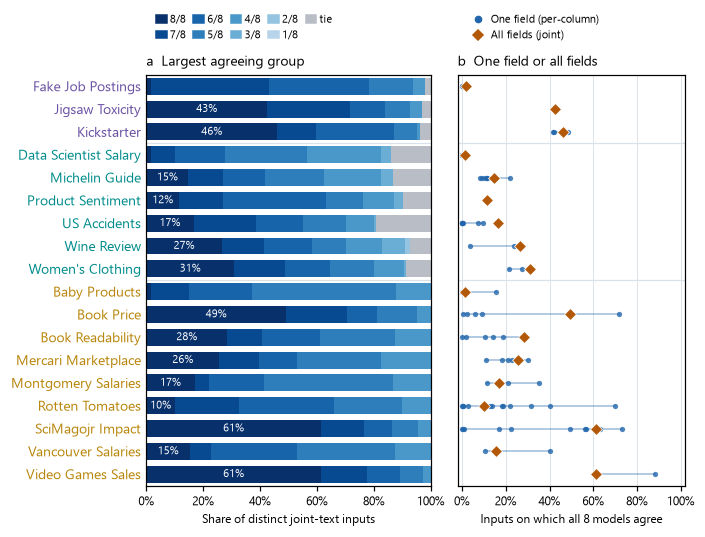

dataset,position,text_column,unanimous,n
Baby Products,Least consensus,company_struct,0.000000,193
Baby Products,Most consensus,colors,0.157534,146
Book Price,Least consensus,Author,0.003546,3102
Book Price,Most consensus,Edition,0.717110,2934
Book Readability,Least consensus,British Words,0.000000,250
Book Readability,Most consensus,Anthology,0.289655,290
dataset,position,text_column,unanimous,n
Baby Products,Least consensus,company_struct,0.000000,193
Baby Products,Most consensus,colors,0.157534,146
Book Price,Least consensus,Author,0.003546,3102


weighting,dataset,rows,unique_inputs,change_pp
,Video Games Sales,0.540,0.614,-7.336
,Vancouver Salaries,0.111,0.154,-4.277
,Book Price,0.487,0.491,-0.386
,US Accidents,0.163,0.166,-0.343
,Data Scientist Salary,0.014,0.016,-0.182
,Wine Review,0.264,0.265,-0.163
weighting,dataset,rows,unique_inputs,change_pp
,Video Games Sales,0.540,0.614,-7.336
,Vancouver Salaries,0.111,0.154,-4.277
,Book Price,0.487,0.491,-0.386


In [2]:
report_section("2. All-model consensus and the presented text")
for fig, name, caption in plots.consensus_figure(result):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)
if not row_summary.empty:
    fields = row_summary.query("representation == 'per_column' and weighting == 'unique_inputs'")
    extremes = pd.concat([fields.loc[fields.groupby("dataset").unanimous.idxmin()].assign(position="Least consensus"), fields.loc[fields.groupby("dataset").unanimous.idxmax()].assign(position="Most consensus")]).sort_values(["dataset", "position"])
    display_table("Text fields with the least and most consensus", extremes[["dataset", "position", "text_column", "unanimous", "n"]], preview_rows=6)
    reuse = row_summary[row_summary.representation.eq("joint")].pivot(index="dataset", columns="weighting", values="unanimous")
    reuse = reuse.assign(change_pp=100 * (reuse.rows - reuse.unique_inputs)).sort_values("change_pp")
    display_table("Unanimous share: source rows minus distinct inputs (percentage points)", reuse.round(3), preview_rows=6)
    record(reuse, "Duplicate-weighting sensitivity of joint-text consensus")
record(result.table("vote_patterns"), "Complete vote patterns, including ties, under both weightings")
record(row_summary, "All-model consensus and probability-distance summaries")

## Relation to frozen embeddings

In [3]:
record("Planned low-cost extension: on the same RQ1C row sample, compare pairwise frozen-vector cosine distances with decision-vector total-variation distances within each dataset and text field. Keep all three encoders; average within datasets, not across raw coordinates. No inference or trained decoder is needed when vectors exist. Similarity is not proof of retained target information; predictive utility belongs to RQ2.", "Embedding geometry extension (not yet executed)")

## Complete report

In [4]:
finish_report(NOTEBOOK, save.summary() + "\nOnly saved evidence was analysed; no inference, model training or live VSC changes were performed.")

rq1/02_context

1. Compared models and denominators

Decision model  Complete blocks  Expected blocks
      Jev 1.14                0               36
  Liquid d1-3B               36               36
  Liquid d1-2B                0               36
Perplexity 27B               36               36
    Clef-flash               36               36
    Strands 2B               36               36
     Intern 4B               36               36
        H2O 4B               36               36
       SII 27B               36               36
       Kev 27B                0               36
      D3-turbo               36               36
     Nimble 9B                0               36
     GLiDE 27B                0               36
   Mammoth 27B                0               36
  Drex Max 27B                0               36


Rows, distinct joint inputs and rows without any text
              dataset  models  source_rows  unique_inputs  missing_joint_rows
    Fake Job Postings       8